In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from optimizer import grid_search, strategy_compare
from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
SEARCH_SPACE = {
    "threshold_ma200_sell": [1.5, 2.0],
    "threshold_bolinger_sell": [1.5, 2.0, 2.5],
    "threshold_rsi_sell": [70.0, 75.0, 80.0],
    "threshold_ppo_sell": [5.0, 10.0, 15.0],
}

In [15]:
STRATEGIES = {
    "BuyHold": {"classic_dca": True},
    "Default": {},
    "NoConfirm": {"manual_sell_fraction": 0.5, "minimum_profit": 2.0},
    "Experiment": {"threshold_ma200_sell": 1.5, "threshold_bolinger_sell": 2.0, "threshold_rsi_sell": 70.0, "threshold_ppo_sell": 10.0}
}

In [5]:
df_prices = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True).dropna(axis=1)
df_prices

,BTC,ETH,XRP,USDT,BCH,LTC,EOS,BNB,BSV,XLM,...,MKR,ONT,DOGE,VET,BAT,OMG,SNX,ZRX,ICX,QTUM
Date,,,,,,,,,,,,,,,,,,,,,
2020-02-13,10214.379883,268.099243,0.326706,0.998579,474.317993,80.403427,5.341575,25.440100,359.041138,0.082655,...,625.763184,1.021036,0.003026,0.008026,0.295389,1.280141,0.932967,0.320865,0.394342,2.842507
2020-02-14,10312.116211,284.217499,0.334822,1.000114,491.160645,82.990349,5.361947,26.296959,360.390015,0.085796,...,638.993713,1.071109,0.003130,0.008323,0.311020,1.370907,0.992797,0.345264,0.400229,3.015611
2020-02-15,9889.424805,264.728577,0.306236,0.999128,437.664948,76.513245,4.743118,24.149651,310.077820,0.079246,...,607.280212,0.957589,0.002920,0.007440,0.280342,1.289413,0.949770,0.317226,0.360399,2.677241
2020-02-16,9934.433594,259.894714,0.295034,0.999272,415.940643,75.152588,4.412250,23.466389,285.867523,0.075079,...,634.711975,0.909603,0.002774,0.007133,0.264260,1.190897,0.945258,0.299002,0.348740,2.511193
2020-02-17,9690.142578,266.363434,0.286572,0.998474,409.344574,73.251305,4.346360,23.551378,309.441620,0.071851,...,614.943604,0.878514,0.002712,0.006756,0.266563,1.169630,1.011205,0.291352,0.344687,2.499368
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-03-31,68233.312500,2104.708252,1.340259,0.999024,466.334564,53.917908,0.075516,617.049194,13.852106,0.167265,...,1740.242554,0.083272,0.092208,0.006763,0.096228,0.054769,0.287147,0.103136,0.034007,0.887649
2026-04-01,68078.554688,2138.737061,1.347766,0.999800,454.311554,53.805855,0.078632,610.622986,14.003111,0.169253,...,1785.234497,0.112436,0.092191,0.006885,0.099325,0.055448,0.281543,0.104537,0.035458,0.930321
2026-04-02,66888.570312,2056.852539,1.318691,0.999892,444.056213,52.260174,0.076542,583.136841,14.614312,0.163015,...,1750.205811,0.108114,0.090374,0.006740,0.094341,0.053399,0.278585,0.102121,0.035270,0.879604


# SEARCH

In [6]:
history_search = grid_search(
    prices=df_prices, 
    param_grid=SEARCH_SPACE, 
    n_boot=100,
    sample_size=10,
    sequence_length=365 * 3,
    )

100%|██████████| 54/54 [38:43<00:00, 43.03s/it]


In [7]:
history_search

,strategy,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,Avg_price,Num_take_profits,MDD,MDD_usd,MA200_survival_days,RoAC,iteration
0,threshold_ma200_sell=1.5_threshold_bolinger_se...,XLM,1692,1082,900,1335,1983,36,0.134156,7,-24,-220,32.500000,173,1
1,threshold_ma200_sell=1.5_threshold_bolinger_se...,ZEC,1851,260,1231,1727,1491,19,38.599796,7,-37,-548,11.083333,-4,1
2,threshold_ma200_sell=1.5_threshold_bolinger_se...,ZEC,1940,0,1562,1940,1562,13,38.299225,8,-52,-588,2.000000,-29,1
3,threshold_ma200_sell=1.5_threshold_bolinger_se...,XLM,1692,1093,750,1325,1844,36,0.134784,7,-24,-220,119.600000,174,1
4,threshold_ma200_sell=1.5_threshold_bolinger_se...,XRP,1544,3453,257,115,3711,65,0.957422,6,-32,-368,39.000000,171,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53995,threshold_ma200_sell=2.0_threshold_bolinger_se...,ONT,1940,52,1130,1918,1182,29,0.289422,9,-70,-689,279.000000,-5,100
53996,threshold_ma200_sell=2.0_threshold_bolinger_se...,ETH,1544,291,1682,1353,1974,83,2067.843751,2,-51,-1252,91.000000,34,100
53997,threshold_ma200_sell=2.0_threshold_bolinger_se...,LTC,1643,0,1661,1643,1661,31,82.994219,2,-47,-660,20.000000,-11,100
53998,threshold_ma200_sell=2.0_threshold_bolinger_se...,ICX,1702,0,792,1702,792,40,0.146962,3,-63,-946,93.000000,-6,100


In [8]:
search_res = history_search.groupby("strategy").agg(
    RoAC=("RoAC", "mean"),
    MDD=("MDD", "mean"),
    MDD_usd=("MDD_usd", "mean"),
    Portfolio=("Portfolio", "mean"),
    Realized_cash=("Realized_cash", "mean"),
    Cash_spent=("Cash_spent", "mean"),
    Total_value_mean=("Total_value", "mean"),
    Total_value_meadian=("Total_value", "median"),
    Total_value_low=("Total_value", lambda s: np.percentile(s, 25)),
    Total_value_high=("Total_value", lambda s: np.percentile(s, 75)),
)

search_res.sort_values("RoAC", ascending=False).style.background_gradient(cmap="RdYlGn", axis=0).format("{:.2f}")

,RoAC,MDD,MDD_usd,Portfolio,Realized_cash,Cash_spent,Total_value_mean,Total_value_meadian,Total_value_low,Total_value_high
strategy,,,,,,,,,,
threshold_ma200_sell=1.5_threshold_bolinger_sell=2.0_threshold_rsi_sell=80.0_threshold_ppo_sell=10.0,105.01,-37.01,-545.13,969.32,1374.26,1670.74,2344.03,2162.50,1758.25,2598.00
threshold_ma200_sell=1.5_threshold_bolinger_sell=2.5_threshold_rsi_sell=80.0_threshold_ppo_sell=10.0,103.31,-38.55,-589.36,1042.80,1301.27,1678.53,2344.51,2130.50,1705.00,2629.25
threshold_ma200_sell=1.5_threshold_bolinger_sell=2.5_threshold_rsi_sell=70.0_threshold_ppo_sell=10.0,98.81,-37.90,-532.82,1000.92,1345.72,1671.72,2347.05,2201.50,1759.75,2651.25
threshold_ma200_sell=1.5_threshold_bolinger_sell=2.5_threshold_rsi_sell=75.0_threshold_ppo_sell=15.0,97.83,-39.48,-578.65,992.30,1331.32,1676.24,2324.06,2212.50,1757.75,2630.00
threshold_ma200_sell=1.5_threshold_bolinger_sell=2.5_threshold_rsi_sell=75.0_threshold_ppo_sell=10.0,95.51,-39.59,-617.15,1035.71,1313.20,1680.30,2349.34,2183.00,1706.25,2641.75
threshold_ma200_sell=2.0_threshold_bolinger_sell=2.0_threshold_rsi_sell=75.0_threshold_ppo_sell=5.0,94.45,-36.84,-531.06,927.34,1328.14,1666.64,2255.93,2161.50,1764.75,2579.25
threshold_ma200_sell=1.5_threshold_bolinger_sell=2.0_threshold_rsi_sell=75.0_threshold_ppo_sell=5.0,94.07,-36.73,-501.02,914.54,1317.44,1680.14,2232.43,2148.00,1718.00,2556.00
threshold_ma200_sell=1.5_threshold_bolinger_sell=2.0_threshold_rsi_sell=70.0_threshold_ppo_sell=15.0,93.97,-38.33,-528.07,910.08,1377.81,1673.15,2288.31,2137.50,1752.00,2587.75
threshold_ma200_sell=1.5_threshold_bolinger_sell=1.5_threshold_rsi_sell=70.0_threshold_ppo_sell=15.0,93.84,-37.46,-516.12,935.07,1364.64,1666.26,2300.17,2194.50,1760.25,2627.50


In [14]:
search_res.loc['threshold_ma200_sell=1.5_threshold_bolinger_sell=2.0_threshold_rsi_sell=70.0_threshold_ppo_sell=10.0']

RoAC                     92.498
MDD                     -38.129
MDD_usd                -535.199
Portfolio               953.483
Realized_cash          1402.352
Cash_spent             1676.198
Total_value_mean       2356.283
Total_value_meadian    2218.000
Total_value_low        1751.500
Total_value_high       2704.000
Name: threshold_ma200_sell=1.5_threshold_bolinger_sell=2.0_threshold_rsi_sell=70.0_threshold_ppo_sell=10.0, dtype: float64

# COMPARE

In [16]:
history_compare = strategy_compare(
    prices=df_prices,
    strategies=STRATEGIES,
    n_boot=100,
    sample_size=10,
    sequence_length=365 * 3,
)

100%|██████████| 4/4 [02:41<00:00, 40.37s/it]


In [17]:
history_compare

,strategy,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,Avg_price,Num_take_profits,MDD,MDD_usd,MA200_survival_days,RoAC,iteration
0,BuyHold,XLM,1544,0,1524,1544,1524,45,0.140904,0,-72,-1396,61.000000,35,1
1,BuyHold,QTUM,1544,0,598,1544,598,36,2.460270,0,-71,-1342,34.000000,-4,1
2,BuyHold,XLM,1554,0,1208,1554,1208,15,0.144851,0,-53,-423,125.250000,-26,1
3,BuyHold,ZRX,1544,0,2351,1544,2351,41,0.302509,0,-78,-4371,161.000000,5,1
4,BuyHold,BTC,1544,0,3716,1544,3716,71,33494.049878,0,-31,-1111,32.285714,56,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,Experiment,OMG,1821,1596,518,1175,2115,43,1.799818,10,-53,-626,215.500000,228,100
3996,Experiment,DASH,1960,524,864,1772,1389,32,52.058598,10,-39,-770,202.000000,54,100
3997,Experiment,OMG,1999,874,671,1595,1545,28,1.128708,13,-41,-781,240.000000,73,100
3998,Experiment,LTC,1544,1492,533,589,2026,55,91.596179,3,-34,-317,51.600000,55,100


In [18]:
compare_res = history_compare.groupby("strategy").agg(
    RoAC=("RoAC", "mean"),
    MDD=("MDD", "mean"),
    MDD_usd=("MDD_usd", "mean"),
    Portfolio=("Portfolio", "mean"),
    Realized_cash=("Realized_cash", "mean"),
    Cash_spent=("Cash_spent", "mean"),
    Total_value_mean=("Total_value", "mean"),
    Total_value_meadian=("Total_value", "median"),
    Total_value_low=("Total_value", lambda s: np.percentile(s, 25)),
    Total_value_high=("Total_value", lambda s: np.percentile(s, 75)),
)

compare_res.sort_values("RoAC", ascending=False).style.background_gradient(cmap="RdYlGn", axis=0).format("{:.2f}")

,RoAC,MDD,MDD_usd,Portfolio,Realized_cash,Cash_spent,Total_value_mean,Total_value_meadian,Total_value_low,Total_value_high
strategy,,,,,,,,,,
Experiment,98.16,-37.38,-529.40,941.97,1380.69,1666.48,2323.08,2183.00,1754.50,2631.00
Default,86.02,-39.76,-725.51,1188.81,1174.42,1678.54,2363.67,2130.00,1642.00,2766.25
NoConfirm,85.80,-41.06,-704.79,1139.14,1118.13,1674.58,2257.61,2184.00,1544.00,2815.50
BuyHold,29.38,-60.95,-2271.70,1973.34,0.00,1548.44,1973.34,1528.50,1038.00,2335.75


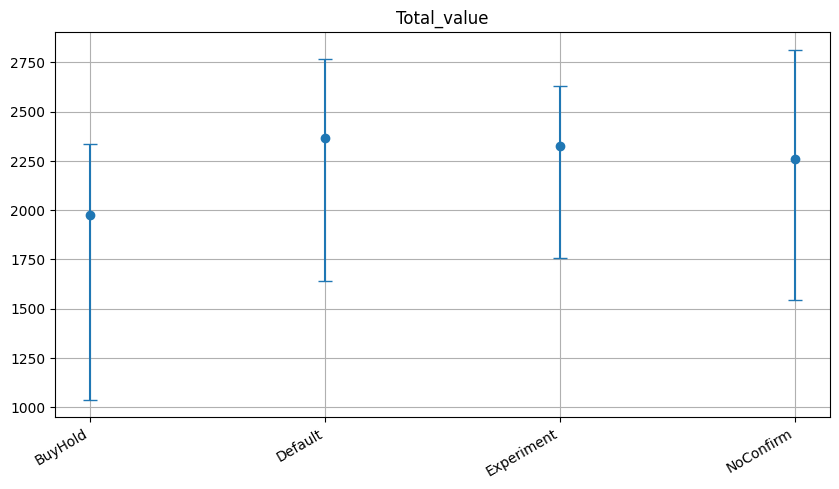

In [19]:
metric = "Total_value"

plt.figure(figsize=(10, 5))

means = compare_res[f"{metric}_mean"]
low = compare_res[f"{metric}_low"]
high = compare_res[f"{metric}_high"]

plt.errorbar(
    means.index,
    means.values,
    yerr=[means - low, high - means],
    fmt="o",
    capsize=5,
)
plt.title(metric)
plt.xticks(rotation=30, ha="right")
plt.grid()
plt.show()